In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

df = pd.read_csv("../data/processed/cleaned_arabam.csv")
print(f"Cleaned Data Ingested: {df.shape[0]} rows, {df.shape[1]} columns\n")

display(df.head(3))

Cleaned Data Ingested: 1000 rows, 18 columns



,price,brand,series,model,year,kilometer,transmission,fuel_type,body_type,color,engine_displacement_cc,engine_power_hp,drivetrain,avg_fuel_consumption,painted_count,local_painted_count,changed_count,is_original
0,1135000.0,Toyota,Yaris,1.5 Fun Special,2017.0,98800.0,Otomatik,Benzin,Hatchback/5,Beyaz,1496.0,111.0,Önden Çekiş,4.8,0.0,0.0,0.0,1.0
1,660000.0,Volkswagen,Polo,1.4 Tdi Comfortline,2014.0,283000.0,Yarı Otomatik,Dizel,Hatchback/5,Siyah,1422.0,90.0,Önden Çekiş,3.5,7.0,0.0,2.0,0.0
2,1380000.0,Toyota,Corolla,1.8 Hybrid Dream,2021.0,172000.0,Otomatik,Hibrit,Sedan,Beyaz,1798.0,122.0,Önden Çekiş,3.5,0.0,1.0,0.0,0.0


# 1. Target Variable Analysis (Price)
In this section, we analyze the distribution of the target variable `price`, calculate its skewness, and evaluate the effect of log-transformation (`log1p`).

--- Price Descriptive Statistics ---
count        1,000.00
mean     1,061,107.24
std        763,325.67
min         60,000.00
25%        615,000.00
50%        900,000.00
75%      1,306,250.00
max      9,140,000.00
Name: price, dtype: object

Price Distribution Skewness: 3.43


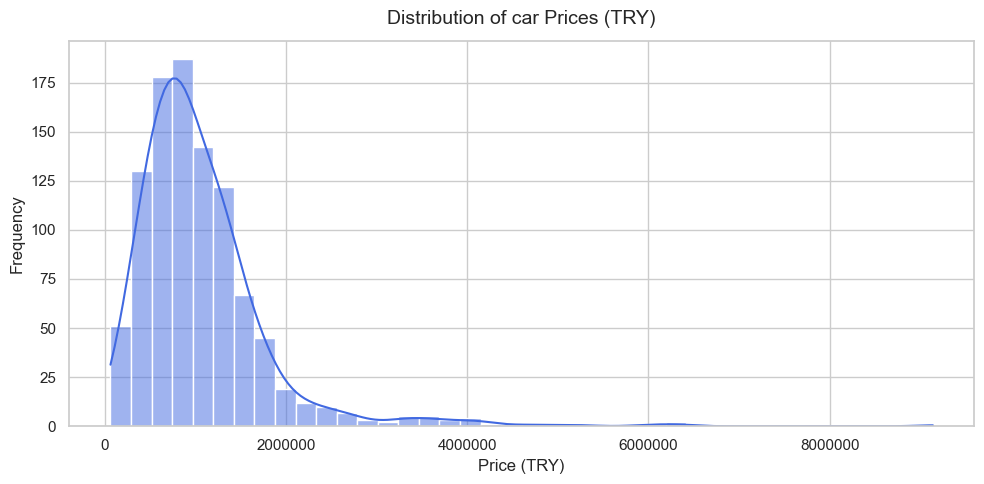

In [2]:
price_desc = df["price"].describe()
print("--- Price Descriptive Statistics ---")
print(price_desc.apply(lambda x: f"{x:,.2f}"))

skew_val = df["price"].skew()
print(f"\nPrice Distribution Skewness: {skew_val:.2f}")

fig, ax = plt.subplots(figsize=(10, 5))
sns.histplot(df["price"], kde=True, bins=40, color="royalblue", ax=ax)
ax.set_title("Distribution of car Prices (TRY)", fontsize=14, pad=12)
ax.set_xlabel("Price (TRY)", fontsize=12)
ax.set_ylabel("Frequency", fontsize=12)
ax.ticklabel_format(style="plain", axis="x")

plt.tight_layout()
plt.show()

Original Price Skewness: 3.43
Log-transformed Price Skewness: -0.34


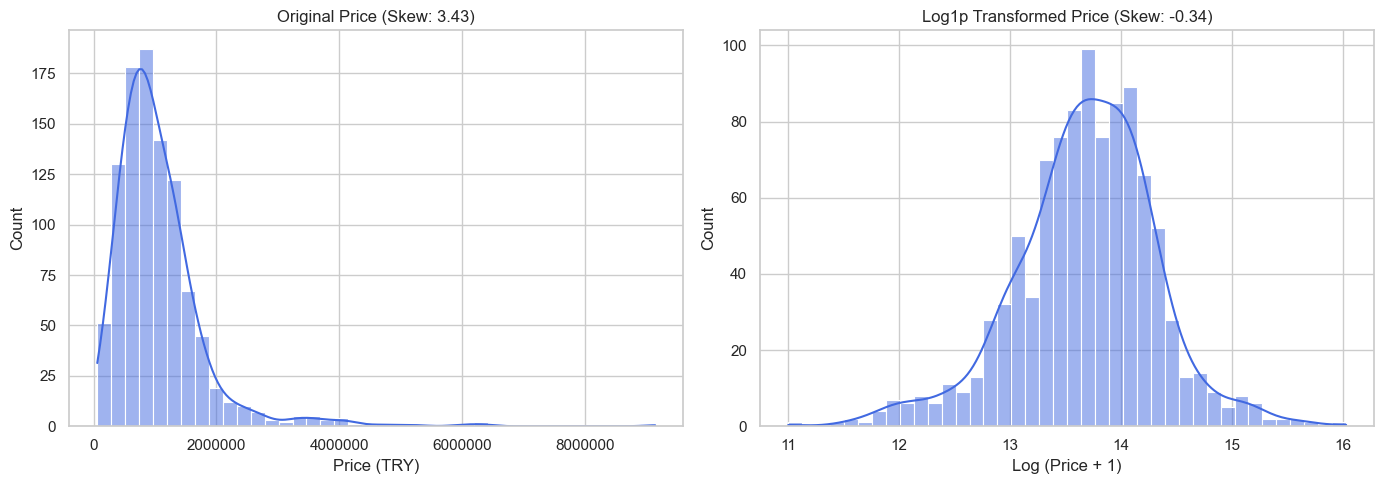

In [3]:
original_skew = df["price"].skew()
log_price = np.log1p(df["price"])
log_skew = log_price.skew()
print(f"Original Price Skewness: {original_skew:.2f}")
print(f"Log-transformed Price Skewness: {log_skew:.2f}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(df["price"], kde=True, bins=40, color="royalblue", ax=ax1)
ax1.set_title(f"Original Price (Skew: {original_skew:.2f})", fontsize=12)
ax1.set_xlabel("Price (TRY)")
ax1.ticklabel_format(style="plain", axis="x")

sns.histplot(log_price, kde=True, bins=40, color="royalblue", ax=ax2)
ax2.set_title(f"Log1p Transformed Price (Skew: {log_skew:.2f})", fontsize=12)
ax2.set_xlabel("Log (Price + 1)")

plt.tight_layout()
plt.show()

> **Key Takeaway & Modeling Decision:**
> - The target variable (`price`) exhibits severe positive skewness (**3.43**), driven by high-end luxury outliers reaching up to 9.14M TRY.
> - Applying natural log transformation (`np.log1p`) successfully normalizes the distribution, reducing skewness to **-0.34**.
> - **Decision:** Target transformation ($\log(1 + y)$) will be integrated into the regression pipeline to stabilize variance and prevent prediction bias on budget/mid-range segments.

# 2. Numerical Feature Relationships & Correlation
Analyzing the relationship between key numerical variables (kilometer, model year, engine specs) and price to identify potential predictive features and multicollinearity.

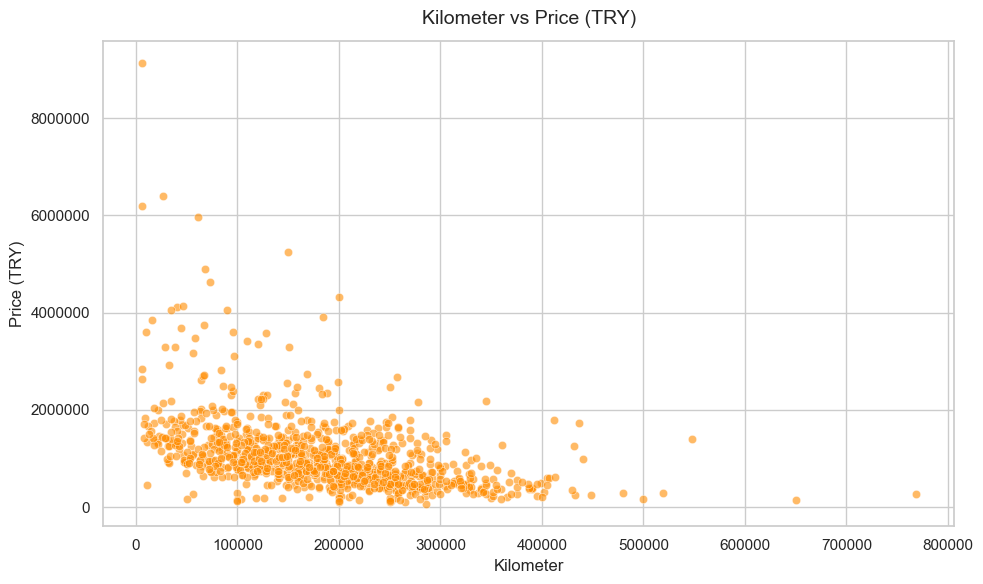

In [4]:
plt.figure(figsize=(10, 6))

sns.scatterplot(data=df, x="kilometer", y="price", alpha=0.6, color="darkorange", edgecolor="w")
plt.title("Kilometer vs Price (TRY)", fontsize=14, pad=12)
plt.xlabel("Kilometer", fontsize=12)
plt.ylabel("Price (TRY)", fontsize=12)
plt.ticklabel_format(style="plain", axis="both")

plt.tight_layout()
plt.show()

> **Key Takeaway:**
> - A clear negative trend is observed: vehicle valuation drops steadily beyond **200,000 km**, with almost all vehicles over 300,000 km trading under 2M TRY.
> - High price variance between 0–100,000 km indicates that mileage alone is insufficient to determine price; brand tier and engine output act as major confounding factors.

### Correlation Heatmap (Numerical Features)
Examines the linear correlation coefficients between price and numerical vehicle specifications.

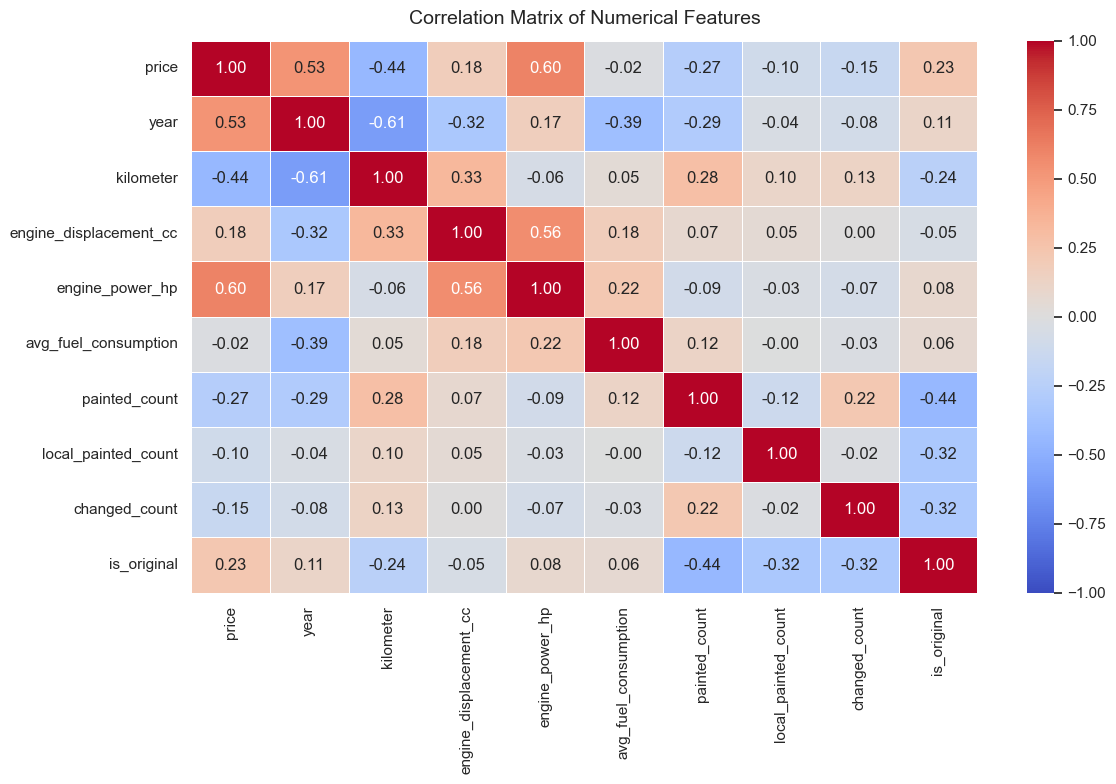

--- Correlation with Price ---
price                     1.000000
engine_power_hp           0.601899
year                      0.527975
is_original               0.232959
engine_displacement_cc    0.176055
avg_fuel_consumption     -0.020418
local_painted_count      -0.096264
changed_count            -0.149571
painted_count            -0.268129
kilometer                -0.441404
Name: price, dtype: float64


In [5]:
numeric_cols = df.select_dtypes(include=[np.number]).columns
corr_matrix = df[numeric_cols].corr()

plt.figure(figsize=(12, 8))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, linewidths=0.5)
plt.title("Correlation Matrix of Numerical Features", fontsize=14, pad=12)
plt.tight_layout()
plt.show()

print("--- Correlation with Price ---")
print(corr_matrix["price"].sort_values(ascending=False))

> **Key Takeaway & Feature Insights:**
> - **Top Price Drivers (+):** `engine_power_hp` (**+0.60**) and `year` (**+0.53**) demonstrate the strongest positive linear relationships with valuation.
> - **Top Depreciation Drivers (-):** `kilometer` (**-0.44**) and `painted_count` (**-0.27**) cause the highest drop in resale value.
> - **Damage Hierarchy:** Full panel repainting (`painted_count`) impacts price more severely than localized repairs (`local_painted_count`: **-0.10**).

# 3. Categorical Feature Analysis (Brand, Transmission, Fuel Type)
Investigating how vehicle segment, brand identity, transmission type, and fuel category impact car valuation using aggregation tables and boxplots.

--- Top 12 Brands: Price Summary (Sorted by Median) ---


,count,mean,median
brand,,,
Mercedes - Benz,48,"2,044,104 TL","1,712,500 TL"
Audi,33,"1,923,482 TL","1,600,000 TL"
Bmw,63,"1,812,016 TL","1,478,500 TL"
Skoda,38,"1,395,592 TL","1,299,500 TL"
Toyota,49,"1,101,968 TL","1,080,000 TL"
Volkswagen,130,"1,090,868 TL","1,055,000 TL"
Hyundai,59,"917,034 TL","950,000 TL"
Renault,183,"867,520 TL","829,000 TL"
Ford,61,"832,945 TL","755,000 TL"


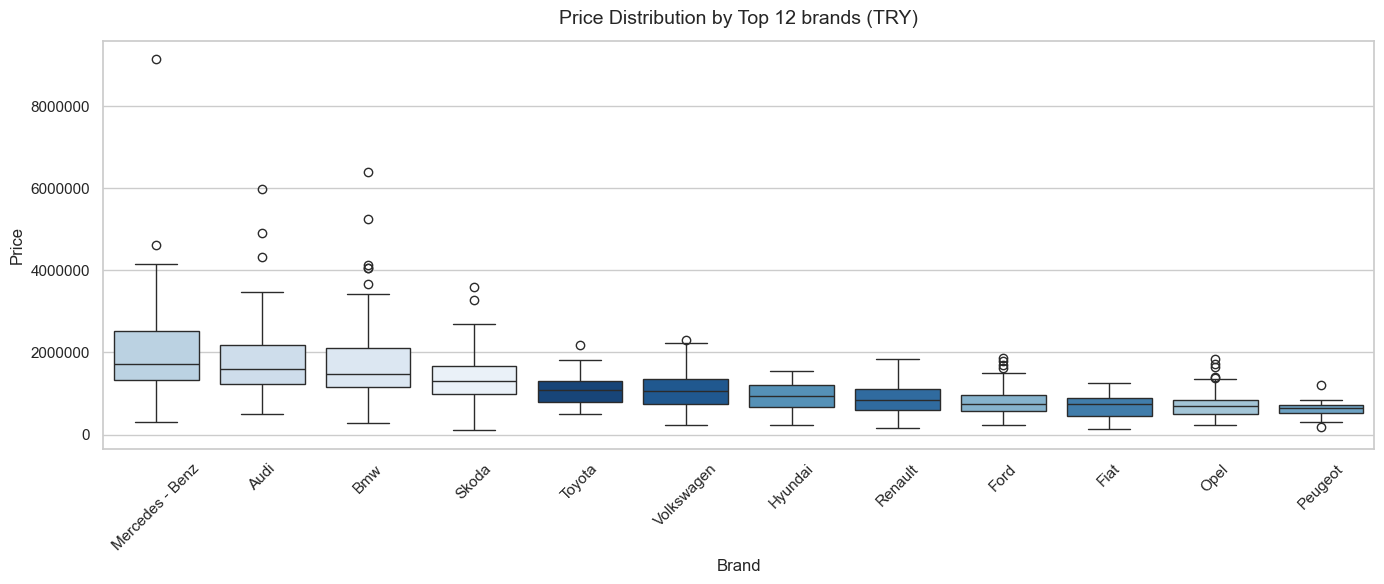

In [7]:
top_brands = df["brand"].value_counts().head(12).index
df_top_brands = df[df["brand"].isin(top_brands)]

brand_stats = df_top_brands.groupby("brand")["price"].agg(["count", "mean", "median"]).sort_values(by="median", ascending=False)
print("--- Top 12 Brands: Price Summary (Sorted by Median) ---")
formatted_stats = brand_stats.copy()
formatted_stats["mean"] = formatted_stats["mean"].apply(lambda x: f"{x:,.0f} TL")
formatted_stats["median"] = formatted_stats["median"].apply(lambda x: f"{x:,.0f} TL")
display(formatted_stats)

plt.figure(figsize=(14, 6))
sns.boxplot(data=df_top_brands, x="brand", y="price", order=brand_stats.index, hue="brand", palette="Blues_r", legend=False)
plt.title("Price Distribution by Top 12 brands (TRY)", fontsize=14, pad=12)
plt.xlabel("Brand", fontsize=12)
plt.ylabel("Price", fontsize=12)
plt.xticks(rotation=45)
plt.ticklabel_format(style="plain", axis="y")

plt.tight_layout()
plt.show()

> **Key Takeaway:**
> - Distinct market segmentation: Premium brands (**Mercedes-Benz, Audi, BMW**) show significantly higher median prices and wider interquartile ranges (IQR).
> - High-price outliers (e.g., Mercedes at 9.14M TRY) originate from premium brand flagships.
> - Volume brands (**Fiat, Renault, Opel, Peugeot**) exhibit tight, predictable valuation bands, forming a homogeneous economy class.

### 3.1 Transmission and Fuel Type Impact on Price
Comparing price distributions across transmission mechanisms (Automatic vs Manual) and fuel technologies.

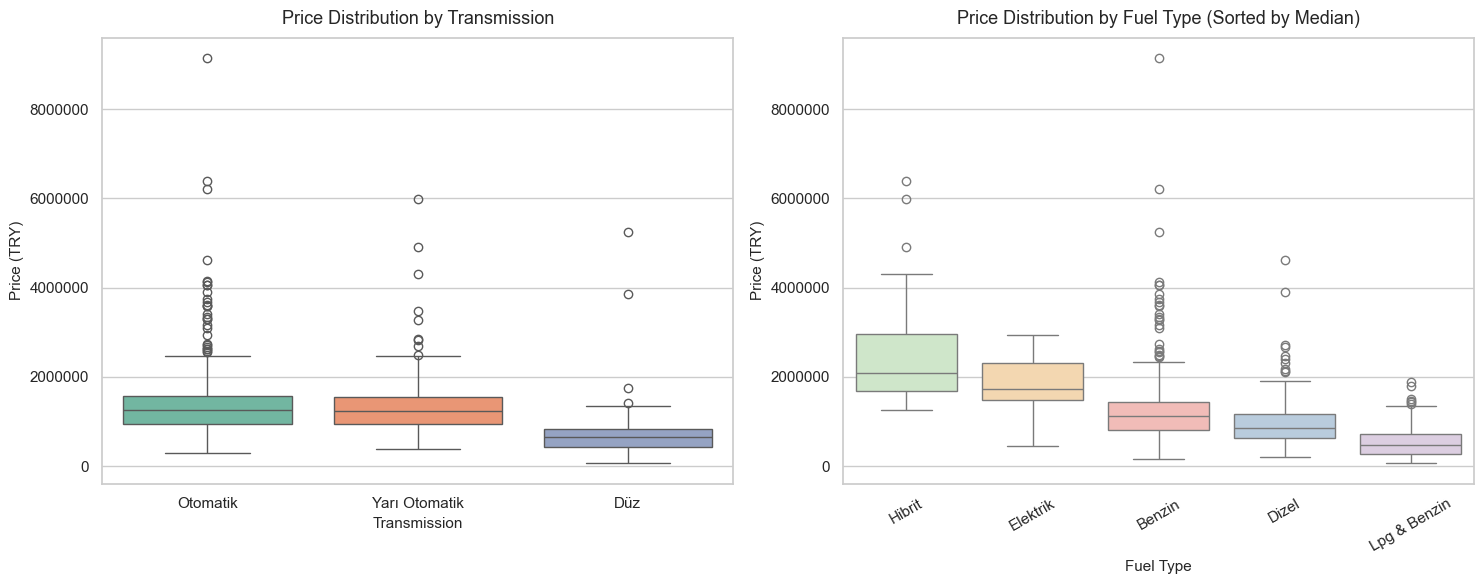

--- Median Price by transmission ---
transmission
Düz                642,500 TL
Otomatik         1,265,000 TL
Yarı Otomatik    1,224,750 TL
Name: price, dtype: object
--- Median Price by Fuel Type ---
fuel_type
Hibrit          2,097,500 TL
Elektrik        1,737,000 TL
Benzin          1,130,000 TL
Dizel             855,000 TL
Lpg & Benzin      475,000 TL
Name: price, dtype: object


In [8]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

sns.boxplot(data=df, x="transmission", y="price", hue="transmission", palette="Set2", legend=False, ax=ax1)
ax1.set_title("Price Distribution by Transmission", fontsize=13, pad=10)
ax1.set_xlabel("Transmission", fontsize=11)
ax1.set_ylabel("Price (TRY)", fontsize=11)
ax1.ticklabel_format(style="plain", axis="y")

fuel_order = df.groupby("fuel_type")["price"].median().sort_values(ascending=False).index
sns.boxplot(data=df, x="fuel_type", y="price", order=fuel_order, hue="fuel_type", palette="Pastel1", legend=False, ax=ax2)
ax2.set_title("Price Distribution by Fuel Type (Sorted by Median)", fontsize=13, pad=10)
ax2.set_xlabel("Fuel Type", fontsize=11)
ax2.set_ylabel("Price (TRY)", fontsize=11)
ax2.tick_params(axis="x", rotation=30)
ax2.ticklabel_format(style="plain", axis="y")

plt.tight_layout()
plt.show()

print("--- Median Price by transmission ---")
print(df.groupby("transmission")["price"].median().apply(lambda x: f"{x:,.0f} TL"))

print("--- Median Price by Fuel Type ---")
print(df.groupby("fuel_type")["price"].median().sort_values(ascending=False).apply(lambda x: f"{x:,.0f} TL"))

> **Key Takeaway & Domain Insights:**
> - **Transmission Premium:** Automatic (~1.27M TRY) and Semi-Automatic (~1.22M TRY) vehicles hold nearly **2x** the median price of Manual vehicles (~643K TRY), serving as a primary differentiator between economy and modern/premium segments.
> - **Fuel Technology Hierarchy:** Hybrid (2.10M TRY) and Electric (1.74M TRY) vehicles command the highest median values due to recent model years and modern powertrain technologies.
> - **Economy Segment Baseline:** LPG & Gasoline vehicles form the absolute entry-level price floor (median: 475K TRY) with minimal price variance.